# Notebook 03b — Journey Conversion Modeling (LogReg + XGBoost) with Calibration & SHAP

🎯 **Objective**  
Build supervised models to predict whether a **user journey converts (0/1)** using compact, leak-free, journey-level features.  
Deliver **well-calibrated probabilities** for decisioning (e.g., bid multipliers, budget allocation, frequency capping) and **global model explanations** via SHAP.  
Also derive a **model-based campaign attribution** view from SHAP contributions of first/last campaign IDs.

---

## 🧩 Inputs

- Journeys (all, converted & non-converted): `../data/processed/journeys_all.parquet`  
  Columns used:  
  `uid, conversion, campaign_seq, click_seq, cost_seq, time_since_last_click_seq`
- (From Notebook 03 for later fusion) Campaign metrics & attributions (optional)

**Dataset scale (this run)**  
- Journeys: **6,814,951** rows × 13 columns  
- Label balance: **0 → 6,008,755**, **1 → 806,196** (≈ 11.8% positive)

---

## 🧱 Feature Engineering 

**Sequence handling & coercion**
- Robust `to_pylist` to parse lists from arrays/strings/nulls.

**Journey features**
- `path_length` = len(campaign_seq) **(clipped at 20)**  
- `num_clicks`  = sum(click_seq) **(clipped at 20)**  
- `unique_campaigns` = `nunique(campaign_seq)`
- **Costs** (log1p to stabilize tails):
  - `total_cost = log1p(sum(cost_seq))`
  - `avg_cost   = log1p(mean(cost_seq))`
- **Time gaps**:
  - `avg_time_gap = log1p(mean(non-negative time_since_last_click_seq))`
- **Coded IDs for modeling**:
  - `first_campaign`, `last_campaign` as categorical codes (kept raw as `_first_campaign_id`, `_last_campaign_id` for OHE & SHAP)

**Final feature table**
- Shape: **(6,814,951, 12)** → `uid`, `conversion`, 10 model features  
- No label leakage: features computed only from journey internals (no future info).

---

## ✂️ Train / Val / Test Split

Stratified 70/15/15 on **journeys**:
- Train: **4,770,465** rows  
- Val:   **1,022,243** rows  
- Test:  **1,022,243** rows

---

## 🔧 Baseline Model — Logistic Regression (balanced)

**Preprocessing**
- Numeric: `StandardScaler`  
- Categorical: **Top-K 300** for `_first_campaign_id`, `_last_campaign_id`, then `OneHotEncoder(handle_unknown="ignore")`  
  - Others bucketed as `__OTHER__`
- Class imbalance: `class_weight="balanced"`

**Pipeline**: `ColumnTransformer` → `LogisticRegression(max_iter=1000)`  

**Validation/Test (uncalibrated baseline)**  
- **VAL** — AUC **0.8716**, LogLoss **0.4528**, PR-AUC **0.5588**, Brier **0.1406**  
- **TEST** — AUC **0.8725**, LogLoss **0.4519**, PR-AUC **0.5604**, Brier **0.1404**

**Probability calibration (fit on VAL)**
- `CalibratedClassifierCV(method="isotonic", cv="prefit")`
- `CalibratedClassifierCV(method="sigmoid",  cv="prefit")`

**TEST (calibrated)**
- **Isotonic** — AUC **0.8728**, LogLoss **0.2476**, PR-AUC **0.5543**, Brier **0.0727**  
- **Sigmoid**  — AUC **0.8725**, LogLoss **0.2548**, PR-AUC **0.5604**, Brier **0.0735**  

> 📌 *Calibration slashes LogLoss/Brier (quality of probabilities) with flat AUC — expected, since AUC is rank-based.*

**Artifacts**
- `../artifacts/models/logreg_uncalibrated.joblib`  
- `../artifacts/models/logreg_calibrated.joblib`

---

## 🚀 Gradient Boosting — XGBoost (class-imbalanced)

**Preprocessing for trees**
- Numeric passthrough + One-Hot (same Top-K) → **sparse CSR**  
- DMatrix: `xgb.DMatrix(X, label=y)`

**Params (key)**
objective=binary:logistic, eval_metric=[logloss, auc],
eta=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
scale_pos_weight = (neg/pos), seed=42


**Training**
- `num_boost_round=2000`, `early_stopping_rounds=100` on VAL

**Best model (this run)**
- Best iteration: **1999**  
- **VAL** — AUC **0.9586**, LogLoss **0.2611**  
- **TEST** — AUC **0.9588**, LogLoss **0.2611**

**Isotonic calibration (fit on VAL, applied to TEST)**
- **TEST** — AUC **0.9588**, LogLoss **0.1490**, PR-AUC **0.8138**, Brier **0.0450**  
  *(Uncalibrated TEST: AUC **0.9588**, LogLoss **0.2611**, PR-AUC **0.8170**, Brier **0.0878**)*

> 📌 *Again, strong reduction in LogLoss/Brier = far better probability quality; AUC stable.*

**Artifacts**
- `../artifacts/models/xgb_booster.json`  
- `../artifacts/models/pre_xgb_onehot.joblib` (OHE mapping for reproducible inference/SHAP)  
- `../artifacts/models/xgb_booster_for_calibration.joblib`  
- `../artifacts/models/xgb_iso_calibrator.joblib`

---

## 🔍 Explainability — SHAP (Global)

**Method**
- `shap.TreeExplainer(booster)` on **CSR-encoded** test matrix
- Feature names = numerics + `OneHotEncoder.get_feature_names_out` for:
  - `_first_campaign_topk`
  - `_last_campaign_topk`

**Top global drivers (mean |SHAP|)**
1. `num_clicks` *(dominant)*
2. `avg_time_gap`
3. `path_length`
4. `avg_cost`
5. `unique_campaigns`
6. `total_cost`
7–… **Last-campaign** one-hots:  
   `_last_campaign_topk_10341182`, `_9100693`, `_15184511`, `_30801593`, `_32368244`, `_2869134`, …

> Interpretation: **engagement density** (clicks, path length, recency proxies) and **last-touch campaign identity** are key for conversion lift — consistent with retargeting dynamics.

---

## 🧾 Model-Based Campaign Attribution (from SHAP)

**Goal**  
Translate model explanations into a **campaign share of modeled conversion lift**, focusing on *which campaign appears at the first/last position*.

**How**  
- From one-hot blocks, pick the active SHAP value per row for:
  - `_first_campaign_topk`
  - `_last_campaign_topk`
- Keep **converted** journeys only to be consistent with rule-based attribution framing.
- Aggregate **positive SHAP** (and raw, signed) by `campaign_id`:
  - `first_pos`, `last_pos`, `credit_pos_total = first_pos + last_pos`
  - Shares: `share_pos`, `share_raw`

**Output (sample heads shown in code)** — top campaigns by `credit_pos_total` include:  
`10341182, 32368244, 15184511, 9100693, 2869134, 16184517, 9100692, 25920690, 5544859, 15398570, …`

**Artifact**
- `../artifacts/bi_exports/model_based_attribution_shap.csv`

> 📌 *This complements heuristic attribution (Notebook 03) with a **data-driven** view: which campaigns’ presence at **first/last** positions contributes most to predicted conversion lift.*

---

## 📈 Why this notebook matters

- **Decision-ready probabilities**: After calibration, scores can drive thresholds, CRM cuts, bidding tiers, or simulator inputs.  
- **Auditable logic**: Global SHAP exposes *why* the model thinks a journey will convert (click density, last-touch identity).  
- **Bridging to budget**: SHAP-based attribution offers an alternate lens to the **rule-based** credit from Notebook 03; comparing both strengthens planning.  
- **Production-friendly**: Artifacts (preprocessors + models + calibrators) ensure stable inference and reproducible SHAP.

---

## 📂 Outputs 

**Models & Preprocessors**
- `../artifacts/models/logreg_uncalibrated.joblib`  
- `../artifacts/models/logreg_calibrated.joblib`  
- `../artifacts/models/xgb_booster.json`  
- `../artifacts/models/pre_xgb_onehot.joblib`  
- `../artifacts/models/xgb_booster_for_calibration.joblib`  
- `../artifacts/models/xgb_iso_calibrator.joblib`

**Explanations & BI**
- `../artifacts/bi_exports/model_based_attribution_shap.csv` *(campaign-level SHAP-credit, first/last)*

---

## 🔌 How this fits the pipeline
1. **Notebook 01 — Data Preprocessing & EDA** 
   Prepare impression-level data, KPIs, and Parquet artifacts.
2. **Notebook 02 — Build User Journeys**  
   Convert impressions → ordered user journeys with sequences.
3. **Notebook 03 — Attribution & Modeling (3a–3c)**  
   - **03a — Heuristic Attribution:** First/Last/Linear/Time-decay over journeys.  
   - **03b — Journey Conversion Modeling:** Logistic Regression & XGBoost with calibration + SHAP.(This)  
   - **03c — Shapley Attribution (Monte Carlo):** Model-based credit per campaign.
4. **Notebook 04 — Attribution Rollups, ROI & Rule-vs-Model Comparison**  
   Consolidate attributions, compute ROI, compare methods.
5. **Notebook 05 — Customer Segmentation & Audience Exports**  
   KMeans segmentation, campaign-mix profiles, and BI exports.
6. **Notebook 06 — Budget Reallocation Simulator (Upcoming)**  
   What-if scenarios using attributed ROI and constraints.

---

## 🛠️ Repro / Notes

- Keep **Top-K caps** stable across train/val/test; persist the **preprocessor** you fit on train.  
- Always **calibrate on validation**, apply to test/production.  
- For thresholded classification (not shown), tune on **VAL** via F1/precision-recall or expected value.  
- SHAP on CSR is memory-heavy; sample test if needed.

---


In [3]:
pip install --upgrade xgboost

Note: you may need to restart the kernel to use updated packages.


*Import & Load Journeys*

In [6]:
import pandas as pd
import numpy as np
import ast

# Load journeys
journeys_path = "../data/processed/journeys_all.parquet"
J = pd.read_parquet(journeys_path)

print("Journeys shape:", J.shape)
display(J.head(3))


Journeys shape: (6814951, 13)


,uid,conversion,conversion_id,conv_time,length,campaign_seq,click_seq,cost_seq,time_since_last_click_seq,first_campaign_id,last_campaign_id,total_cost,num_clicks
0,10000148,0,-1,-1,16,"[13166099, 31772643, 31772643, 31772643, 31772...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0001880141207948327, 9.999999747378752e-06,...","[220193.0, 269760.0, 666201.0, 666771.0, 70166...",13166099,13166099,0.001507,0
1,10001508,0,-1,-1,27,"[20916101, 20916101, 20916101, 20916101, 20916...","[0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, ...","[2.388120992691256e-05, 0.00011574133532121778...","[330658.0, 330719.0, 1523.0, 2387.0, 56549.0, ...",20916101,15654890,0.002062,16
2,1000222,0,-1,-1,7,"[26321366, 26321366, 26321366, 26321366, 26321...","[1, 0, 0, 1, 1, 0, 1]","[8.647569484310225e-05, 9.956641588360071e-05,...","[134205.0, 208040.0, 462542.0, 606775.0, 241.0...",26321366,26321366,0.000852,4


In [7]:
print(J["conversion"].value_counts())

conversion
0    6008755
1     806196
Name: count, dtype: int64


*Feature Engineering*

In [11]:
import numpy as np
import pandas as pd
import ast

# --- helpers ---
def to_pylist(x):
    if isinstance(x, list): return x
    if isinstance(x, (np.ndarray, pd.Series)): return x.tolist()
    if isinstance(x, str) and x.strip().startswith('[') and x.strip().endswith(']'):
        try: return ast.literal_eval(x)
        except Exception: return []
    if x is None or (isinstance(x, float) and pd.isna(x)) or x == "": return []
    return [x]

def mean_nonneg(xs):
    xs = [t for t in xs if isinstance(t,(int,float)) and t >= 0]
    return float(np.mean(xs)) if xs else 0.0

# Ensure sequence columns are real lists
for c in ["campaign_seq","click_seq","cost_seq","time_since_last_click_seq"]:
    if c in J.columns:
        J[c] = J[c].apply(to_pylist)
    else:
        J[c] = [[] for _ in range(len(J))]

# Feature Engineering with outlier handling 
features = pd.DataFrame()
features["uid"] = J["uid"]

# target: 'conversion' (journeys_all); 
if "conversion" in J.columns:
    features["conversion"] = J["conversion"].astype(int)
elif "attribution" in J.columns:
    features["conversion"] = J["attribution"].astype(int)
else:
    raise KeyError("Neither 'conversion' nor 'attribution' found in journeys dataframe.")

# path stats
features["path_length"] = J["campaign_seq"].apply(len).clip(upper=20)
features["num_clicks"]  = J["click_seq"].apply(lambda x: int(np.sum(x))).clip(upper=20)
features["unique_campaigns"] = J["campaign_seq"].apply(lambda x: len(set(x)))

# costs (log1p)
features["total_cost"] = J["cost_seq"].apply(np.sum).astype(float)
features["avg_cost"]   = J["cost_seq"].apply(lambda x: float(np.mean(x)) if len(x)>0 else 0.0)
features["total_cost"] = np.log1p(features["total_cost"])
features["avg_cost"]   = np.log1p(features["avg_cost"])

# time gaps (seconds; -1 means none) -> mean of non-negatives, then log1p
features["avg_time_gap"] = J["time_since_last_click_seq"].apply(mean_nonneg)
features["avg_time_gap"] = np.log1p(features["avg_time_gap"])

# first/last campaign (codes for model)
first_ids = J["campaign_seq"].apply(lambda s: str(s[0]) if len(s)>0 else "-1")
last_ids  = J["campaign_seq"].apply(lambda s: str(s[-1]) if len(s)>0 else "-1")
features["first_campaign"] = pd.Categorical(first_ids).codes
features["last_campaign"]  = pd.Categorical(last_ids).codes

# keep raw IDs for later SHAP aggregation
features["_first_campaign_id"] = first_ids
features["_last_campaign_id"]  = last_ids

print("Feature table with outlier handling:", features.shape)
display(features.head())
print("Label balance (conversion):")
print(features["conversion"].value_counts(dropna=False))


Feature table with outlier handling: (6814951, 12)


,uid,conversion,path_length,num_clicks,unique_campaigns,total_cost,avg_cost,avg_time_gap,first_campaign,last_campaign,_first_campaign_id,_last_campaign_id
0,10000148,0,16,0,2,0.001506,0.000094,13.949503,66,66,13166099,13166099
1,10001508,0,20,16,4,0.002060,0.000076,12.548960,230,135,20916101,15654890
2,1000222,0,7,4,1,0.000851,0.000122,12.498953,331,331,26321366,26321366
3,10007459,0,1,0,1,0.000038,0.000038,14.378747,471,471,30801593,30801593
4,10009337,0,3,1,1,0.000075,0.000025,12.461126,7,7,10341182,10341182


Label balance (conversion):
conversion
0    6008755
1     806196
Name: count, dtype: int64


*Train Val Test Split*

In [13]:
from sklearn.model_selection import train_test_split

# X = features (without uid/label)
X = features.drop(columns=['uid','conversion'])
y = features['conversion']

# First split: Train vs Temp(Val+Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Second split: Validation vs Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print("Train size:", X_train.shape)
print("Validation size:", X_val.shape)
print("Test size:", X_test.shape)


Train size: (4770465, 10)
Validation size: (1022243, 10)
Test size: (1022243, 10)


*Logistic Regression with scaling*

In [15]:
import numpy as np
import pandas as pd
import json

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, log_loss, average_precision_score, brier_score_loss
)
from sklearn.calibration import calibration_curve

# 1) Columns
numeric_cols = ["path_length","num_clicks","unique_campaigns","total_cost","avg_cost","avg_time_gap"]
cat_cols_src = ["_first_campaign_id","_last_campaign_id"]   # raw string IDs

assert all(c in features.columns for c in numeric_cols + cat_cols_src), "Missing required columns."

X_full = features[numeric_cols + cat_cols_src].copy()
y_full = features["conversion"].astype(int).copy()

# 2) Split (70/15/15)
X_train, X_temp, y_train, y_temp = train_test_split(
    X_full, y_full, test_size=0.30, random_state=42, stratify=y_full
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)


# 3) Top-K cap for high-cardinality categories (fitted on TRAIN only)
TOPK = 300

def reduce_topk_fit(series: pd.Series, k: int):
    vc = series.value_counts()
    return set(vc.head(k).index.tolist())

def reduce_topk_transform(series: pd.Series, keep: set):
    return series.where(series.isin(keep), "__OTHER__")

keep_first = reduce_topk_fit(X_train["_first_campaign_id"], TOPK)
keep_last  = reduce_topk_fit(X_train["_last_campaign_id"],  TOPK)

X_train["_first_campaign_topk"] = reduce_topk_transform(X_train["_first_campaign_id"], keep_first)
X_train["_last_campaign_topk"]  = reduce_topk_transform(X_train["_last_campaign_id"],  keep_last)

for df in (X_val, X_test):
    df["_first_campaign_topk"] = reduce_topk_transform(df["_first_campaign_id"], keep_first)
    df["_last_campaign_topk"]  = reduce_topk_transform(df["_last_campaign_id"],  keep_last)

cat_cols_topk = ["_first_campaign_topk","_last_campaign_topk"]
input_cols = numeric_cols + cat_cols_topk


# 4) Pipeline (OneHot + Standardize + LogReg)
#    If sklearn < 1.2 replace sparse_output=True with sparse=True

pre = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=True, dtype=np.float32), cat_cols_topk),
    ],
    remainder="drop",
    sparse_threshold=1.0,
)

logreg = LogisticRegression(max_iter=1000, class_weight="balanced")
pipe = Pipeline([("pre", pre), ("clf", logreg)])


# 5) Train + Baseline metrics
pipe.fit(X_train[input_cols], y_train)

def eval_split(name, probs, y_true):
    metrics = {
        "split": name,
        "roc_auc": roc_auc_score(y_true, probs),
        "logloss": log_loss(y_true, probs),
        "pr_auc": average_precision_score(y_true, probs),
        "brier": brier_score_loss(y_true, probs),
    }
    frac_pos, mean_pred = calibration_curve(y_true, probs, n_bins=10, strategy="uniform")
    metrics["calib_curve_frac_pos"]  = frac_pos.tolist()
    metrics["calib_curve_mean_pred"] = mean_pred.tolist()
    return metrics

proba_val  = pipe.predict_proba(X_val[input_cols])[:, 1]
proba_test = pipe.predict_proba(X_test[input_cols])[:, 1]

val_base  = eval_split("val_baseline",  proba_val,  y_val)
test_base = eval_split("test_baseline", proba_test, y_test)

print("Baseline (VAL):",  json.dumps({k:v for k,v in val_base.items()  if not k.startswith("calib")}, indent=2))
print("Baseline (TEST):", json.dumps({k:v for k,v in test_base.items() if not k.startswith("calib")}, indent=2))


Baseline (VAL): {
  "split": "val_baseline",
  "roc_auc": 0.8716399183932856,
  "logloss": 0.45276258804098546,
  "pr_auc": 0.5588266878424317,
  "brier": 0.14056267333398959
}
Baseline (TEST): {
  "split": "test_baseline",
  "roc_auc": 0.8724612479750663,
  "logloss": 0.4518890112964322,
  "pr_auc": 0.5604219853570106,
  "brier": 0.14040446336459156
}


In [16]:
from sklearn.calibration import CalibratedClassifierCV

# Using the *fitted* pipeline; wraping it with a calibrator
calib_iso = CalibratedClassifierCV(estimator=pipe, method="isotonic", cv="prefit")
calib_iso.fit(X_val[input_cols], y_val)

calib_sig = CalibratedClassifierCV(estimator=pipe, method="sigmoid", cv="prefit")
calib_sig.fit(X_val[input_cols], y_val)

# Evaluating calibrated vs baseline on TEST
proba_iso  = calib_iso.predict_proba(X_test[input_cols])[:, 1]
proba_sig  = calib_sig.predict_proba(X_test[input_cols])[:, 1]

test_iso = eval_split("test_calibrated_isotonic", proba_iso, y_test)
test_sig = eval_split("test_calibrated_sigmoid",  proba_sig, y_test)

import json
print("\nCalibrated (Isotonic, TEST):", json.dumps({k:v for k,v in test_iso.items() if not k.startswith("calib")}, indent=2))
print("Calibrated (Platt/Sigmoid, TEST):", json.dumps({k:v for k,v in test_sig.items() if not k.startswith("calib")}, indent=2))

# Persist the better one (usually isotonic on large data)
from joblib import dump
import os
os.makedirs("../artifacts/models", exist_ok=True)
dump(calib_iso, "../artifacts/models/logreg_calibrated.joblib")
dump(pipe,      "../artifacts/models/logreg_uncalibrated.joblib")
print("\nSaved models -> ../artifacts/models/")


/Users/sayalisawant/Projects/criteo-attribution/.venv/lib/python3.9/site-packages/sklearn/calibration.py:333: UserWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(
/Users/sayalisawant/Projects/criteo-attribution/.venv/lib/python3.9/site-packages/sklearn/calibration.py:333: UserWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(



Calibrated (Isotonic, TEST): {
  "split": "test_calibrated_isotonic",
  "roc_auc": 0.8727551922550102,
  "logloss": 0.24757055215876592,
  "pr_auc": 0.5542982116603934,
  "brier": 0.07268040919038693
}
Calibrated (Platt/Sigmoid, TEST): {
  "split": "test_calibrated_sigmoid",
  "roc_auc": 0.872461247942955,
  "logloss": 0.2547994031352921,
  "pr_auc": 0.5604229066308601,
  "brier": 0.0734759633886341
}

Saved models -> ../artifacts/models/


*XGBoost with early stopping on Validation*

In [21]:
# XGBoost on all journeys (0/1) with sparse one-hot ===
import os, numpy as np, pandas as pd, scipy.sparse as sp
import xgboost as xgb
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_auc_score, log_loss


# Preprocess for XGB: pass numerics, one-hot cats (no scaling for trees)
pre_xgb = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=True, dtype=np.float32), cat_cols_topk),
    ],
    remainder="drop",
    sparse_threshold=1.0,   # keep sparse
)

Xtr_csr  = pre_xgb.fit_transform(X_train[input_cols])
Xval_csr = pre_xgb.transform(X_val[input_cols])
Xte_csr  = pre_xgb.transform(X_test[input_cols])

# DMatrix
dtrain = xgb.DMatrix(Xtr_csr, label=y_train.values)
dval   = xgb.DMatrix(Xval_csr, label=y_val.values)
dtest  = xgb.DMatrix(Xte_csr,  label=y_test.values)

# Set params (handle imbalance)
pos = float(y_train.sum())
neg = float((y_train == 0).sum())
scale_pos_weight = (neg / pos) if pos > 0 else 1.0

params = {
    "objective": "binary:logistic",
    "eval_metric": ["logloss", "auc"],
    "eta": 0.05,
    "max_depth": 6,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "scale_pos_weight": scale_pos_weight,  # <- imbalance handling
    "seed": 42,
}

# Train with early stopping
num_boost_round = 2000
early_stopping_rounds = 100
evals = [(dtrain, "train"), (dval, "val")]

booster = xgb.train(
    params=params,
    dtrain=dtrain,
    num_boost_round=num_boost_round,
    evals=evals,
    early_stopping_rounds=early_stopping_rounds,
    verbose_eval=50
)

print("Best iteration:", booster.best_iteration)
print("Best score:", booster.best_score)

# Predict with best iteration
y_val_proba  = booster.predict(dval,  iteration_range=(0, booster.best_iteration + 1))
y_test_proba = booster.predict(dtest, iteration_range=(0, booster.best_iteration + 1))

print("XGB Validation AUC:",     roc_auc_score(y_val,  y_val_proba))
print("XGB Validation LogLoss:", log_loss(y_val,  y_val_proba))
print("XGB Test AUC:",           roc_auc_score(y_test, y_test_proba))
print("XGB Test LogLoss:",       log_loss(y_test, y_test_proba))

# Save model + the preprocessor ( can reuse for SHAP/production)
os.makedirs("../artifacts/models", exist_ok=True)
booster.save_model("../artifacts/models/xgb_booster.json")

# Save the preprocessor (for consistent one-hot mapping at inference/SHAP time)
from joblib import dump
dump(pre_xgb, "../artifacts/models/pre_xgb_onehot.joblib")
print("Saved -> ../artifacts/models/xgb_booster.json and pre_xgb_onehot.joblib")


[0]	train-logloss:0.66438	train-auc:0.93255	val-logloss:0.66437	val-auc:0.93245
[50]	train-logloss:0.32799	train-auc:0.94359	val-logloss:0.32787	val-auc:0.94333
[100]	train-logloss:0.30145	train-auc:0.94811	val-logloss:0.30139	val-auc:0.94775
[150]	train-logloss:0.29321	train-auc:0.95053	val-logloss:0.29323	val-auc:0.95010
[200]	train-logloss:0.28789	train-auc:0.95215	val-logloss:0.28803	val-auc:0.95163
[250]	train-logloss:0.28438	train-auc:0.95325	val-logloss:0.28461	val-auc:0.95267
[300]	train-logloss:0.28152	train-auc:0.95414	val-logloss:0.28183	val-auc:0.95348
[350]	train-logloss:0.27954	train-auc:0.95480	val-logloss:0.27992	val-auc:0.95409
[400]	train-logloss:0.27765	train-auc:0.95538	val-logloss:0.27810	val-auc:0.95461
[450]	train-logloss:0.27585	train-auc:0.95596	val-logloss:0.27636	val-auc:0.95513
[500]	train-logloss:0.27454	train-auc:0.95637	val-logloss:0.27512	val-auc:0.95548
[550]	train-logloss:0.27338	train-auc:0.95672	val-logloss:0.27405	val-auc:0.95577
[600]	train-logloss

In [22]:
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, log_loss, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve
import numpy as np

# uncalibrated probabilities from trained booster
# the SAME preprocessor
X_val_csr  = pre_xgb.transform(X_val[input_cols])
X_test_csr = pre_xgb.transform(X_test[input_cols])

dval  = xgb.DMatrix(X_val_csr)
dtest = xgb.DMatrix(X_test_csr)

p_val_uncal  = booster.predict(dval,  iteration_range=(0, booster.best_iteration + 1))
p_test_uncal = booster.predict(dtest, iteration_range=(0, booster.best_iteration + 1))
p_val_uncal  = np.clip(p_val_uncal,  1e-12, 1-1e-12)
p_test_uncal = np.clip(p_test_uncal, 1e-12, 1-1e-12)

# Fitting isotonic map on validation
iso = IsotonicRegression(out_of_bounds="clip")
iso.fit(p_val_uncal, y_val.values)

# Apply to test
p_test_iso = iso.transform(p_test_uncal)

def show_metrics(name, p, y):
    fp, mp = calibration_curve(y, p, n_bins=10, strategy="uniform")
    print(f"{name} — AUC:{roc_auc_score(y,p):.6f}  LogLoss:{log_loss(y,p):.6f}  PR-AUC:{average_precision_score(y,p):.6f}  Brier:{brier_score_loss(y,p):.6f}")
    print("  calib mean_pred:", mp.tolist())
    print("  calib frac_pos :", fp.tolist())

print("=== XGB Uncalibrated (TEST) ===")
show_metrics("XGB Uncal", p_test_uncal, y_test.values)

print("\n=== XGB Calibrated (Isotonic, TEST) ===")
show_metrics("XGB Iso", p_test_iso, y_test.values)


=== XGB Uncalibrated (TEST) ===
XGB Uncal — AUC:0.958801  LogLoss:0.261059  PR-AUC:0.817042  Brier:0.087781
  calib mean_pred: [0.005143358595260404, 0.148169862667871, 0.24991400840100908, 0.3498228694955984, 0.4506489078088868, 0.5501521099651746, 0.6490101533657932, 0.7475737911217712, 0.8509941042448677, 0.9744717205207593]
  calib frac_pos : [0.0005608279222201776, 0.020948688037066857, 0.0405576938825649, 0.06535736632824012, 0.09808375245614984, 0.1451662757504682, 0.20648116340318332, 0.3031150544893432, 0.476102135123284, 0.8789039823522582]

=== XGB Calibrated (Isotonic, TEST) ===
XGB Iso — AUC:0.958783  LogLoss:0.149016  PR-AUC:0.813793  Brier:0.045003
  calib mean_pred: [0.013025254049460686, 0.14148057402421965, 0.24181029318094677, 0.35382514867262965, 0.45271000211303297, 0.5444704112812012, 0.6557332241128413, 0.7592120235272116, 0.8544525448691116, 0.9772367116359185]
  calib frac_pos : [0.012844294068526498, 0.14380797652114669, 0.23993554903564043, 0.3585292022792022

In [23]:
from joblib import dump
import os

os.makedirs("../artifacts/models", exist_ok=True)

# Save booster (trained XGBoost model)
dump(booster, "../artifacts/models/xgb_booster_for_calibration.joblib")

# Save isotonic calibrator
dump(iso, "../artifacts/models/xgb_iso_calibrator.joblib")

print("Saved booster and isotonic calibrator.")


Saved booster and isotonic calibrator.


*SHAP: global explanations*

SHAP values shape: (1022243, 608)
Feature count check: True


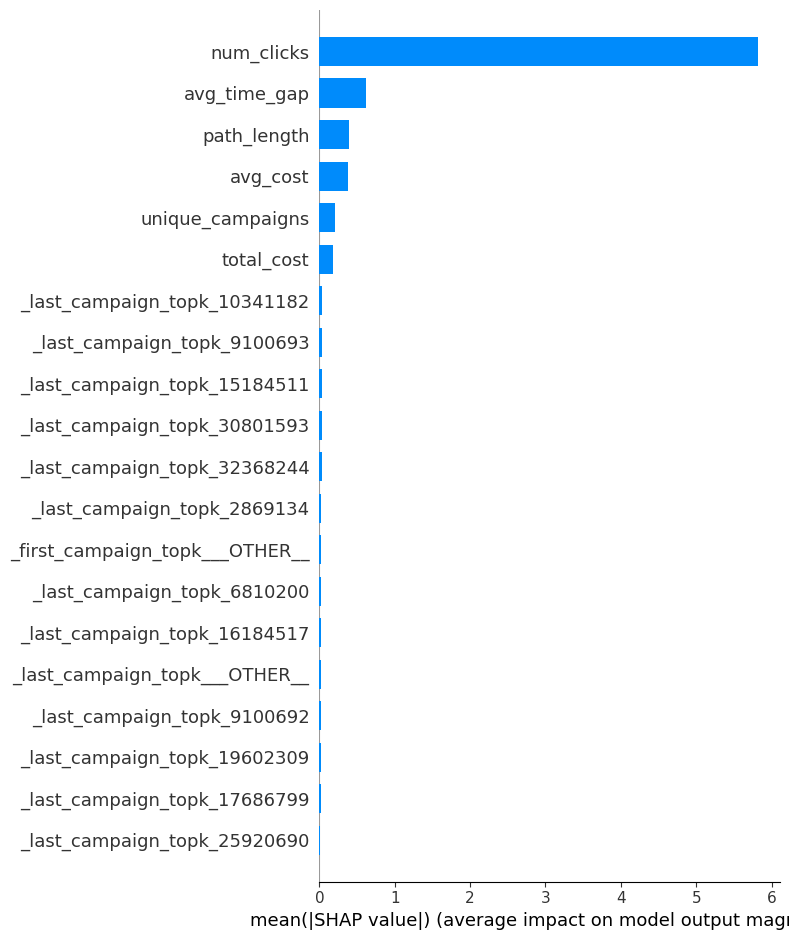

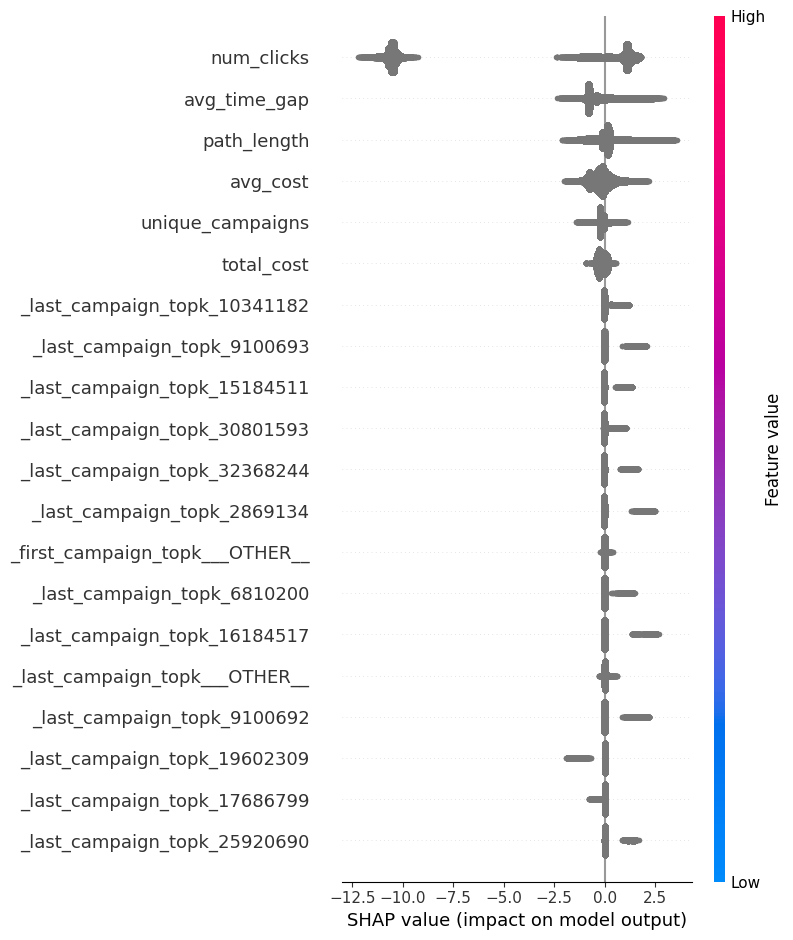

In [27]:
import shap
import numpy as np
import pandas as pd

# Transform test data with the same preprocessor used for training
X_test_csr = pre_xgb.transform(X_test[input_cols])

# Build SHAP explainer on trained booster
explainer = shap.TreeExplainer(booster)

# Compute SHAP values on the transformed test set
shap_values = explainer.shap_values(X_test_csr)

print("SHAP values shape:", shap_values.shape)

# Get feature names for plots
ohe = pre_xgb.named_transformers_['cat']
num_names = numeric_cols
cat_names = ohe.get_feature_names_out(cat_cols_topk).tolist()
feature_names = num_names + cat_names

print("Feature count check:", len(feature_names) == shap_values.shape[1])

# Global importance (mean |SHAP|) bar chart
shap.summary_plot(shap_values, X_test_csr, feature_names=feature_names, plot_type="bar")

# Beeswarm (distribution of SHAP by feature & value)
shap.summary_plot(shap_values, X_test_csr, feature_names=feature_names)


*Tabular feature importance*

In [29]:
# Compute mean |SHAP| per feature
mean_abs = np.abs(shap_values).mean(axis=0)

# Build feature importance table
feat_importance = (
    pd.DataFrame({
        "feature": feature_names,   # <- from numeric + OHE get_feature_names_out
        "mean_abs_shap": mean_abs
    })
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

# Show top 20 features
display(feat_importance.head(20))



,feature,mean_abs_shap
0,num_clicks,5.820927
1,avg_time_gap,0.624121
2,path_length,0.392463
3,avg_cost,0.385638
4,unique_campaigns,0.211998
5,total_cost,0.184911
6,_last_campaign_topk_10341182,0.038476
7,_last_campaign_topk_9100693,0.037303
8,_last_campaign_topk_15184511,0.036369
9,_last_campaign_topk_30801593,0.031534


*Map codes ⇄ campaign IDs (first/last)*

In [28]:
# SHAP → Campaign attribution for one-hot (Top-K) setup 
import numpy as np, pandas as pd, shap, os

# Transform X_test with the SAME preprocessor used for training
X_test_csr = pre_xgb.transform(X_test[input_cols])

# Compute SHAP on encoded features
explainer = shap.TreeExplainer(booster)
shap_values = explainer.shap_values(X_test_csr)  # shape: (n_test, n_features)

# Get feature names to align SHAP columns
ohe = pre_xgb.named_transformers_["cat"]
num_names = numeric_cols
cat_names = ohe.get_feature_names_out(cat_cols_topk).tolist()   # order: first-cat categories, then last-cat
feature_names = num_names + cat_names

# Sanity check
assert shap_values.shape[1] == len(feature_names), "SHAP columns don't match feature_names."

# Locate the blocks for the two categorical features within SHAP columns
n_num = len(num_names)
cats_first = list(ohe.categories_[0])  # for "_first_campaign_topk"
cats_last  = list(ohe.categories_[1])  # for "_last_campaign_topk"

# Indices of one-hot block for first and last campaigns
first_start = n_num
first_end   = n_num + len(cats_first)
last_start  = first_end
last_end    = first_end + len(cats_last)

# Maps from category value -> SHAP column index
first_idx_map = {cat: (first_start + i) for i, cat in enumerate(cats_first)}
last_idx_map  = {cat: (last_start  + i) for i, cat in enumerate(cats_last)}

# For each test row, pick SHAP of the ACTIVE one-hot for first/last campaign
first_vals = X_test["_first_campaign_topk"].astype(str).values
last_vals  = X_test["_last_campaign_topk"].astype(str).values

# Build vectors of SHAP contributions per row for first & last
def pick_active_shap(values, idx_map, default=0.0):
    out = np.zeros(len(values), dtype=np.float64)
    for i, v in enumerate(values):
        j = idx_map.get(v, None)
        if j is not None:
            out[i] = shap_values[i, j]
        else:
            out[i] = 0.0  
    return out

sv_first = pick_active_shap(first_vals, first_idx_map)
sv_last  = pick_active_shap(last_vals,  last_idx_map)

# Keep only converted rows for attribution (so it matches rule-based)
mask_conv = (y_test.values == 1)

def agg_campaign(ids, shap_vec, mask, positive_only=False, colname="credit"):
    vals = np.where(shap_vec > 0, shap_vec, 0.0) if positive_only else shap_vec
    df = pd.DataFrame({"campaign_id": ids, colname: vals, "is_conv": mask})
    df = df[df["is_conv"]]
    return df.groupby("campaign_id", as_index=False)[colname].sum()

# Choose to keep __OTHER__ as its own “campaign” or drop 
KEEP_OTHER = True
first_ids = first_vals.copy()
last_ids  = last_vals.copy()
if not KEEP_OTHER:
    first_mask = first_ids != "__OTHER__"
    last_mask  = last_ids  != "__OTHER__"
else:
    first_mask = np.ones_like(first_vals, dtype=bool)
    last_mask  = np.ones_like(last_vals,  dtype=bool)

# Apply masks to shap vectors too
sv_first_masked = np.where(first_mask, sv_first, 0.0)
sv_last_masked  = np.where(last_mask,  sv_last,  0.0)

first_pos = agg_campaign(first_ids, sv_first_masked, mask_conv, positive_only=True,  colname="first_pos")
last_pos  = agg_campaign(last_ids,  sv_last_masked,  mask_conv, positive_only=True,  colname="last_pos")
first_raw = agg_campaign(first_ids, sv_first_masked, mask_conv, positive_only=False, colname="first_raw")
last_raw  = agg_campaign(last_ids,  sv_last_masked,  mask_conv, positive_only=False, colname="last_raw")

# 7) Merge, totals, shares
camp_attr = (first_pos.merge(last_pos,  on="campaign_id", how="outer")
                      .merge(first_raw, on="campaign_id", how="outer")
                      .merge(last_raw,  on="campaign_id", how="outer")
                      .fillna(0.0))

camp_attr["credit_pos_total"] = camp_attr["first_pos"] + camp_attr["last_pos"]
camp_attr["credit_raw_total"] = camp_attr["first_raw"] + camp_attr["last_raw"]

sum_pos = camp_attr["credit_pos_total"].sum()
sum_raw = camp_attr["credit_raw_total"].sum()
camp_attr["share_pos"] = (camp_attr["credit_pos_total"] / sum_pos) if sum_pos > 0 else 0.0
camp_attr["share_raw"] = (camp_attr["credit_raw_total"] / sum_raw) if sum_raw > 0 else 0.0

# 8) Sort & save for BI
camp_attr = camp_attr.sort_values("credit_pos_total", ascending=False).reset_index(drop=True)
display(camp_attr.head(15))

os.makedirs("../artifacts/bi_exports", exist_ok=True)
out_path = "../artifacts/bi_exports/model_based_attribution_shap.csv"
camp_attr.to_csv(out_path, index=False)
print("Saved ->", out_path)


,campaign_id,first_pos,last_pos,first_raw,last_raw,credit_pos_total,credit_raw_total,share_pos,share_raw
0,10341182,656.406860,6281.597893,654.705289,6281.597893,6938.004753,6936.303182,0.080588,0.091865
1,32368244,2.056482,6782.137780,-205.686362,6782.137780,6784.194263,6576.451419,0.078801,0.087099
2,15184511,194.386259,6314.334803,181.028776,6314.334803,6508.721062,6495.363579,0.075601,0.086025
3,9100693,18.258100,6234.956032,-93.383671,6234.956032,6253.214132,6141.572362,0.072634,0.081339
4,2869134,12.160416,3965.769200,-7.530119,3965.769200,3977.929616,3958.239081,0.046205,0.052423
5,16184517,28.038529,3378.851924,27.320948,3378.851924,3406.890453,3406.172871,0.039572,0.045111
6,9100692,39.402796,2415.490458,36.198134,2415.490458,2454.893253,2451.688591,0.028515,0.032470
7,25920690,0.000000,2255.426219,-113.490900,2255.426219,2255.426219,2141.935318,0.026198,0.028368
8,5544859,0.000000,2208.229114,-228.500904,2208.229114,2208.229114,1979.728210,0.025649,0.026220
9,15398570,814.688565,1313.431027,814.624969,1313.431027,2128.119591,2128.055996,0.024719,0.028184


Saved -> ../artifacts/bi_exports/model_based_attribution_shap.csv
